# Schritt 2 - Real-World-Graphen für Node Failures

Dieses Notebook ist die Paper-nahe Reihe für Real-World-Graphen aus dem alten Zoo-Plot-Notebook `plots_zoo.ipynb`.

- CSV-Dateien werden aus festen Ergebnisordnern geladen.
- `allInOne(...)` berechnet Resilience und durchschnittliche Hops.
- Die 2x3-Übersicht ist wie im Paper-Stil aufgebaut: oben Resilience, unten durchschnittliche Hops.

Der Unterschied zu Schritt 1: Die Algorithmen bleiben gleich, aber die Ausfälle sind Node/Vertex Failures. Ausgefallene Knoten werden intern in alle inzidenten ausgefallenen Kanten übersetzt.

## Technisches Setup

Diese Zelle bereitet nur Pfade, Ausgabeordner und die drei Real-World-Graphen vor.

In [1]:
from pathlib import Path

from IPython.display import Image, display


def find_step2_root():
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if candidate.name == "schritt2_knotenausfaelle":
            return candidate
        nested = candidate / "schritt2_knotenausfaelle"
        if nested.exists():
            return nested
    return Path(r"C:\Users\test\ba-gamous-disjoint\schritt2_knotenausfaelle")


STEP2_ROOT = find_step2_root()
SRC_ROOT = STEP2_ROOT / "src"
DATA_ROOT = STEP2_ROOT / "data" / "topology_zoo"
EVALUATION_ROOT = STEP2_ROOT / "evaluation"
OUTPUT_ROOT = EVALUATION_ROOT / "output"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

REAL_WORLD_GRAPHS = [
    {"label": "attmpls", "title": "ATT-MPLS (n=25)", "nodes": 25, "graphml": DATA_ROOT / "AttMpls.graphml"},
    {"label": "cogentco", "title": "Cogentco (n=197)", "nodes": 197, "graphml": DATA_ROOT / "Cogentco.graphml"},
    {"label": "oteglobe", "title": "Oteglobe (n=93)", "nodes": 93, "graphml": DATA_ROOT / "Oteglobe.graphml"},
]

## GraphML-Dateien

Für die CSV-Erzeugung müssen die drei Topology-Zoo-Dateien im Ordner `schritt2_knotenausfaelle/data/topology_zoo` liegen:

- `AttMpls.graphml`
- `Cogentco.graphml`
- `Oteglobe.graphml`

Das Notebook selbst liest später nur die erzeugten CSV-Dateien. Wenn die GraphML-Dateien oder CSV-Dateien noch fehlen, zeigen die Kontrollzellen das an und die Plot-Zellen werden übersprungen.

In [2]:
def check_graphml_files():
    missing = [graph for graph in REAL_WORLD_GRAPHS if not graph["graphml"].exists()]
    if missing:
        print("GraphML-Dateien fehlen noch:")
        for graph in missing:
            print("-", graph["graphml"])
    else:
        print("Alle GraphML-Dateien sind vorhanden.")
    return missing


missing_graphml = check_graphml_files()

Alle GraphML-Dateien sind vorhanden.


## Auswertungsmethode wie im Paper-Notebook

Die folgende Code-Zelle enthält Hilfsfunktionen für die Auswertung. Sie liest vorhandene CSV-Dateien ein und berechnet daraus Resilience und durchschnittliche Hops.

Die Logik ist bewusst nah an den ursprünglichen Plot-Notebooks gehalten. Für Schritt 2 werden nun Node-Failure-Ergebnisse ausgewertet; die zusätzliche Spalte `nrFailedNodes` kann zur Kontrolle der tatsächlich ausgefallenen Knoten genutzt werden.


In [3]:
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def _mean_or_nan(values):
    return float(np.mean(values)) if len(values) else np.nan


def _filter_arrays_to_success(arr1, arr1_positive, arr2, arr2_positive):
    both_positive = np.logical_and(arr1_positive, arr2_positive)
    return arr1[both_positive], arr2[both_positive]


def allInOne(path, i, rPathsArr, rOneArr, rMultArr, avgHopsPathsArr, avgHopsOneArr, avgHopsMultArr, avgHopsSPArr, printRes=True):
    path = Path(path)
    if not path.exists():
        print(f"Fehlt noch: {path.name}")
        return None

    df = pd.read_csv(path)
    if printRes:
        display(df.head(5))

    hopsRanked = df["hopsRanked"].to_numpy()
    hopsRankedOne = df["hopsRankedOne"].to_numpy()
    hopsPath = df["hopsPath"].to_numpy()
    spLength = df["spLength"].to_numpy()

    hopsRankedPositive = hopsRanked > -1
    hopsRankedOnePositive = hopsRankedOne > -1
    hopsPathPositive = hopsPath > -1
    spLengthPositive = spLength > -1

    total = len(df.index)
    successesRanked = np.count_nonzero(hopsRankedPositive)
    successesRankedOne = np.count_nonzero(hopsRankedOnePositive)
    successesPath = np.count_nonzero(hopsPathPositive)

    avgHopsPath = _mean_or_nan(hopsPath[hopsPathPositive])

    _, hopsRankedFiltered = _filter_arrays_to_success(hopsPath, hopsPathPositive, hopsRanked, hopsRankedPositive)
    avgHopsMult = _mean_or_nan(hopsRankedFiltered)

    _, hopsRankedOneFiltered = _filter_arrays_to_success(hopsPath, hopsPathPositive, hopsRankedOne, hopsRankedOnePositive)
    avgHopsOne = _mean_or_nan(hopsRankedOneFiltered)

    avgSpLength = _mean_or_nan(spLength[spLengthPositive])

    percentPaths = (successesPath / total) * 100
    percentOne = (successesRankedOne / total) * 100
    percentRanked = (successesRanked / total) * 100

    rPathsArr[i] = percentPaths
    rOneArr[i] = percentOne
    rMultArr[i] = percentRanked
    avgHopsPathsArr[i] = avgHopsPath
    avgHopsOneArr[i] = avgHopsOne
    avgHopsMultArr[i] = avgHopsMult
    avgHopsSPArr[i] = avgSpLength

    if printRes:
        print("Resilience Paths: {}%".format(percentPaths))
        print("Resilience One Tree: {}%".format(percentOne))
        print("Resilience Trees: {}%".format(percentRanked))
        print("Avg. failed nodes:", df["nrFailedNodes"].mean() if "nrFailedNodes" in df else "n/a")

    return df


def init_eval_arrays(nrFiles):
    return {
        "rPaths": [np.nan] * nrFiles,
        "rOne": [np.nan] * nrFiles,
        "rMult": [np.nan] * nrFiles,
        "avgHopsPaths": [np.nan] * nrFiles,
        "avgHopsOne": [np.nan] * nrFiles,
        "avgHopsMult": [np.nan] * nrFiles,
        "avgHopsSP": [np.nan] * nrFiles,
    }


def evaluate_series(path_base, files, printRes=False):
    arrays = init_eval_arrays(len(files))
    for i, file_name in enumerate(files):
        allInOne(
            Path(path_base) / file_name,
            i,
            arrays["rPaths"], arrays["rOne"], arrays["rMult"],
            arrays["avgHopsPaths"], arrays["avgHopsOne"], arrays["avgHopsMult"], arrays["avgHopsSP"],
            printRes=printRes,
        )
    return arrays


def plotEval(xVals, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP, xlabel="Failure Rate", title="Failure Rate"):
    edp_patch = mpatches.Patch(color="skyblue", label="EDPs")
    onetree_patch = mpatches.Patch(color="darkred", label="One Tree")
    multtrees_patch = mpatches.Patch(color="lightgreen", label="Multiple Trees")
    both_patch = mpatches.Patch(color="violet", label="EDPs + One Tree")

    plt.plot(xVals, rPaths, marker="o", markerfacecolor="blue", markersize=6, color="skyblue", linewidth=4)
    plt.plot(xVals, rOne, marker="o", markerfacecolor="red", markersize=6, color="darkred", linewidth=4)
    plt.plot(xVals, rMult, marker="o", markerfacecolor="green", markersize=6, color="lightgreen", linewidth=4)
    plt.title(f"Resilience - {title}")
    plt.xlabel(xlabel)
    plt.ylabel("Resilience (%)")
    plt.ylim(-5, 105)
    plt.legend(handles=[edp_patch, onetree_patch, multtrees_patch])
    plt.show()

    plt.plot(xVals, avgHopsPaths, marker="o", markerfacecolor="purple", markersize=6, color="violet", linewidth=4)
    plt.plot(xVals, avgHopsMult, marker="o", markerfacecolor="green", markersize=6, color="lightgreen", linewidth=4)
    plt.title(f"Avg. Hops - {title}")
    plt.xlabel(xlabel)
    plt.ylabel("Average Hops")
    plt.legend(handles=[both_patch, multtrees_patch])
    plt.show()


def plotEvalAx2(xVals, ax, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP, markersize=3, alpha=1):
    linewidth = 2
    ax1, ax2, index = ax

    edp_patch = mpatches.Patch(color="skyblue", label="EDPs")
    onetree_patch = mpatches.Patch(color="darkred", label="One Tree")
    multtrees_patch = mpatches.Patch(color="lightgreen", label="Multiple Trees")
    both_patch = mpatches.Patch(color="violet", label="EDPs + One Tree")

    ax1[index].plot(xVals, rPaths, marker="o", markerfacecolor="blue", markersize=markersize, color="skyblue", linewidth=linewidth, alpha=alpha)
    ax1[index].plot(xVals, rOne, marker="x", markerfacecolor="red", markersize=markersize, color="darkred", linewidth=linewidth, alpha=alpha)
    ax1[index].plot(xVals, rMult, marker="o", markerfacecolor="green", markersize=markersize, color="lightgreen", linewidth=linewidth, alpha=alpha)
    ax1[index].set_ylim(-5, 105)

    if index == 0:
        ax1[index].legend(handles=[edp_patch, onetree_patch, multtrees_patch])

    ax2[index].plot(xVals, avgHopsPaths, marker="o", markerfacecolor="purple", markersize=markersize, color="violet", linewidth=linewidth, alpha=1)
    ax2[index].plot(xVals, avgHopsMult, marker="o", markerfacecolor="green", markersize=markersize, color="lightgreen", linewidth=linewidth, alpha=1)

    if index == 0:
        ax2[index].legend(handles=[both_patch, multtrees_patch])

## CSV-Serien wie im Paper-Notebook

Die Wertebereiche folgen der alten `plots_zoo.ipynb`-Logik:

- Random Failures: Node-Failure-Faktor `1.0` bis `10.0` für die Paper-Subplots.
- Clustered Failures: Failure Rate `0.3` bis `0.9`.

Bei Random Node Failures ist der x-Wert ein Faktor auf `k-1`, wobei `k` die Anzahl der edge-disjoint paths im konkreten Graphen ist. Bei Clustered Node Failures ist der x-Wert eine lokale Start-Rate für die Ausbreitung um den Zielknoten. Die x-Achsen werden daher getrennt interpretiert.

In [4]:
def random_values():
    return [float(x) for x in range(1, 11)]


def clustered_values():
    return [round(x, 1) for x in np.arange(0.3, 1.0, 0.1)]


def format_csv_value(value):
    return str(float(value)) if float(value).is_integer() else str(value)


def csv_name(graph, value):
    return f"trees-n{graph['nodes']}-ff{format_csv_value(value)}.csv"


def series_files(graph, values):
    return [csv_name(graph, value) for value in values]


PILOT_RANDOM_VALUES = [1.0, 2.0, 3.0]
PILOT_CLUSTERED_VALUES = [0.3, 0.6, 0.9]
BA_RANDOM_VALUES = random_values()
BA_CLUSTERED_VALUES = clustered_values()

series_overview = []
for graph in REAL_WORLD_GRAPHS:
    series_overview.append({
        "failure_model": "random",
        "graph": graph["label"],
        "first_value": BA_RANDOM_VALUES[0],
        "last_value": BA_RANDOM_VALUES[-1],
        "expected_csv_files": len(BA_RANDOM_VALUES),
    })
    series_overview.append({
        "failure_model": "clustered",
        "graph": graph["label"],
        "first_value": BA_CLUSTERED_VALUES[0],
        "last_value": BA_CLUSTERED_VALUES[-1],
        "expected_csv_files": len(BA_CLUSTERED_VALUES),
    })

pd.DataFrame(series_overview)

,failure_model,graph,first_value,last_value,expected_csv_files
0,random,attmpls,1.0,10.0,10
1,clustered,attmpls,0.3,0.9,7
2,random,cogentco,1.0,10.0,10
3,clustered,cogentco,0.3,0.9,7
4,random,oteglobe,1.0,10.0,10
5,clustered,oteglobe,0.3,0.9,7


## CSV-Ordner festlegen

Das Notebook zeigt nur auf vorhandene Ergebnisordner und liest die CSV-Dateien daraus ein.

Die Generierung passiert ausserhalb des Plot-Notebooks mit `kResilienceTrees.py`.

In [5]:
def result_dir(failure_model, graph, suffix):
    return SRC_ROOT / f"output_node_zoo_{failure_model}_{graph['label']}_{suffix}"


def check_series_exists(input_dir, files, label):
    input_dir = Path(input_dir)
    missing = [file_name for file_name in files if not (input_dir / file_name).exists()]
    existing_count = len(files) - len(missing)
    if missing:
        print(f"{label}: {existing_count}/{len(files)} CSV-Dateien vorhanden; {len(missing)} fehlen.")
        for file_name in missing[:10]:
            print("-", file_name)
        if len(missing) > 10:
            print("...", len(missing) - 10, "weitere")
    else:
        print(f"{label}: {len(files)}/{len(files)} CSV-Dateien vorhanden.")
    return missing


def all_series_available(failure_model, values, suffix):
    all_missing = []
    for graph in REAL_WORLD_GRAPHS:
        missing = check_series_exists(
            result_dir(failure_model, graph, suffix),
            series_files(graph, values),
            f"{suffix} {failure_model} {graph['label']}",
        )
        all_missing.extend(missing)
    return len(all_missing) == 0

## Hilfsfunktion für 2x3-Paperplots

Diese Funktion baut denselben Plot-Typ wie `plots_zoo.ipynb`: oben Resilience, unten durchschnittliche Hops, nebeneinander für ATT-MPLS, Cogentco und Oteglobe.

Die Funktion liest vorhandene CSV-Serien, speichert den Plot als PNG und SVG und zeigt anschließend das gespeicherte PNG im Notebook an.

In [6]:
def plot_paper_grid(failure_model, values, suffix, output_name, xlabel, figure_title):
    fig, (ax1, ax2) = plt.subplots(2, 3, figsize=(10, 5.8))
    fig.suptitle(figure_title, fontsize=16, fontweight="bold", y=0.98)
    plt.subplots_adjust(left=0.1, bottom=0.1, right=1, top=0.84, wspace=0.15, hspace=0.3)

    fontsize1 = 14
    fontsize2 = 20
    fontsize3 = 14

    for index, graph in enumerate(REAL_WORLD_GRAPHS):
        output_dir = result_dir(failure_model, graph, suffix)
        arrays = evaluate_series(output_dir, series_files(graph, values), printRes=False)

        ax1[index].set_title(graph["title"], fontsize=fontsize1, fontweight="bold")
        ax1[index].set_xlabel(xlabel, labelpad=-1, fontsize=fontsize3)
        ax2[index].set_xlabel(xlabel, labelpad=-1, fontsize=fontsize3)
        if index == 0:
            ax1[index].set_ylabel("Resilience (%)", fontsize=fontsize2)
            ax2[index].set_ylabel("Avg. Hops", fontsize=fontsize2)

        plotEvalAx2(values, (ax1, ax2, index), **arrays, markersize=3, alpha=1)

        if values:
            padding = 0.1 if len(values) == 1 else (max(values) - min(values)) * 0.05
            ax1[index].set_xlim(min(values) - padding, max(values) + padding)
            ax2[index].set_xlim(min(values) - padding, max(values) + padding)

        hop_values = np.array(arrays["avgHopsPaths"] + arrays["avgHopsMult"], dtype=float)
        finite_hops = hop_values[np.isfinite(hop_values)]
        if len(finite_hops) == 0:
            ax2[index].set_ylim(0, 1)
        else:
            ax2[index].set_ylim(0, max(finite_hops) * 1.15)

    output_path = OUTPUT_ROOT / output_name
    fig.savefig(output_path, bbox_inches="tight")
    fig.savefig(output_path.with_suffix(".svg"), bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(output_path)))
    return output_path

## Pilot-CSV-Kontrolle für alle drei Real-World-Graphen

Diese Zelle prüft, ob die kleinen Pilot-CSV-Dateien für ATT-MPLS, Cogentco und Oteglobe vorhanden sind.

In [7]:
pilot_random_available = all_series_available("random", PILOT_RANDOM_VALUES, "pilot5")
pilot_clustered_available = all_series_available("clustered", PILOT_CLUSTERED_VALUES, "pilot5")

pilot5 random attmpls: 3/3 CSV-Dateien vorhanden.
pilot5 random cogentco: 3/3 CSV-Dateien vorhanden.
pilot5 random oteglobe: 3/3 CSV-Dateien vorhanden.
pilot5 clustered attmpls: 3/3 CSV-Dateien vorhanden.
pilot5 clustered cogentco: 3/3 CSV-Dateien vorhanden.
pilot5 clustered oteglobe: 3/3 CSV-Dateien vorhanden.


## Optionaler Pilot-Grid

Diese zwei Zellen erzeugen 2x3-Kontrollplots aus den kleinen Pilot-CSV-Dateien. Für die BA-Auswertung sind die 1000-Run-Plots weiter unten entscheidend; der Pilot-Grid ist nur eine "Vorabkontrolle".

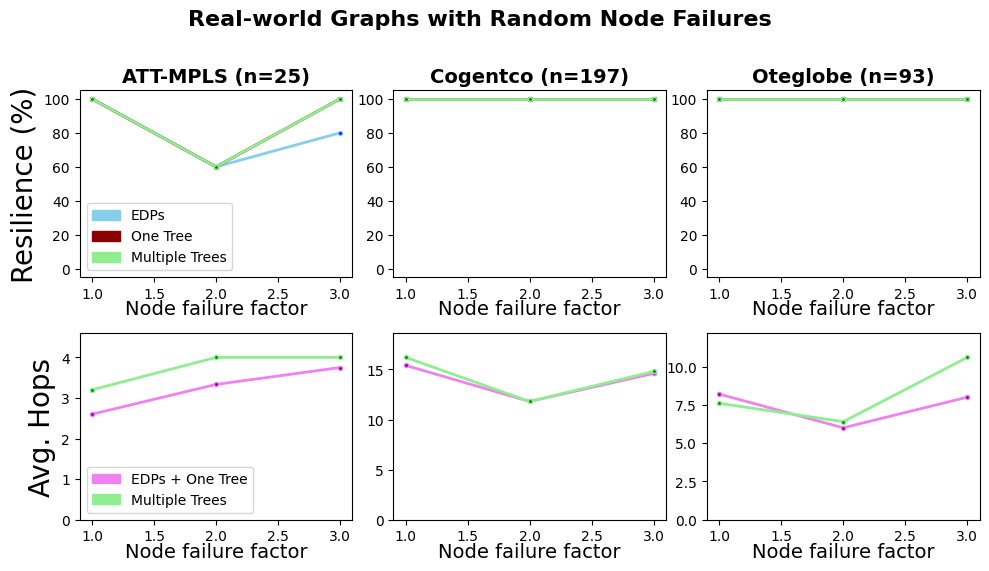

In [8]:
if pilot_random_available:
    random_pilot_grid_path = plot_paper_grid(
        failure_model="random",
        values=PILOT_RANDOM_VALUES,
        suffix="pilot5",
        output_name="notebook_node_zoo_random_paper_pilot5.png",
        xlabel="Node failure factor",
        figure_title="Real-world Graphs with Random Node Failures",
    )
else:
    print("Pilot random CSV-Dateien fehlen noch; Plot wird übersprungen.")

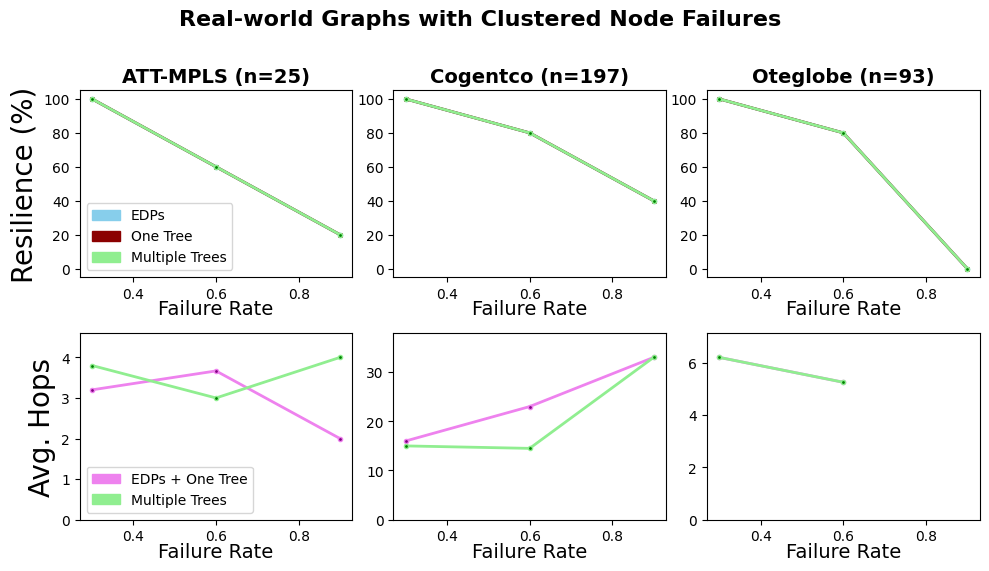

In [9]:
if pilot_clustered_available:
    clustered_pilot_grid_path = plot_paper_grid(
        failure_model="clustered",
        values=PILOT_CLUSTERED_VALUES,
        suffix="pilot5",
        output_name="notebook_node_zoo_clustered_paper_pilot5.png",
        xlabel="Failure Rate",
        figure_title="Real-world Graphs with Clustered Node Failures",
    )
else:
    print("Pilot clustered CSV-Dateien fehlen noch; Plot wird übersprungen.")

## BA-Plots mit 1000 Runs

Diese Zellen erzeugen die finalen 2x3-Plots aus den vorhandenen `runs1000`-CSV-Dateien. Sie pruefen für ATT-MPLS, Cogentco und Oteglobe zuerst, ob alle erwarteten CSV-Dateien vorhanden sind.

Für die BA sind vor allem diese beiden gespeicherten Dateien relevant:

- `notebook_node_zoo_random_paper_runs1000.png`
- `notebook_node_zoo_clustered_paper_runs1000.png`

In [10]:
RUNS1000_SUFFIX = "runs1000"

runs1000_random_available = all_series_available("random", BA_RANDOM_VALUES, RUNS1000_SUFFIX)
runs1000_clustered_available = all_series_available("clustered", BA_CLUSTERED_VALUES, RUNS1000_SUFFIX)

runs1000 random attmpls: 10/10 CSV-Dateien vorhanden.
runs1000 random cogentco: 10/10 CSV-Dateien vorhanden.
runs1000 random oteglobe: 10/10 CSV-Dateien vorhanden.
runs1000 clustered attmpls: 7/7 CSV-Dateien vorhanden.
runs1000 clustered cogentco: 7/7 CSV-Dateien vorhanden.
runs1000 clustered oteglobe: 7/7 CSV-Dateien vorhanden.


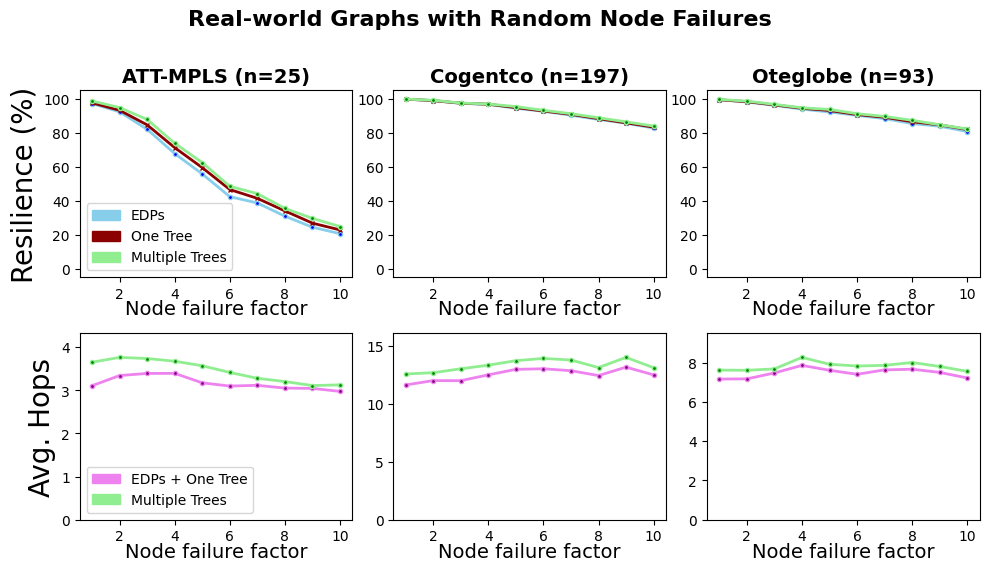

In [11]:
if runs1000_random_available:
    random_runs1000_grid_path = plot_paper_grid(
        "random",
        BA_RANDOM_VALUES,
        RUNS1000_SUFFIX,
        "notebook_node_zoo_random_paper_runs1000.png",
        "Node failure factor",
        "Real-world Graphs with Random Node Failures",
    )
else:
    print("1000-Run random CSV-Dateien fehlen noch; Plot wird übersprungen.")

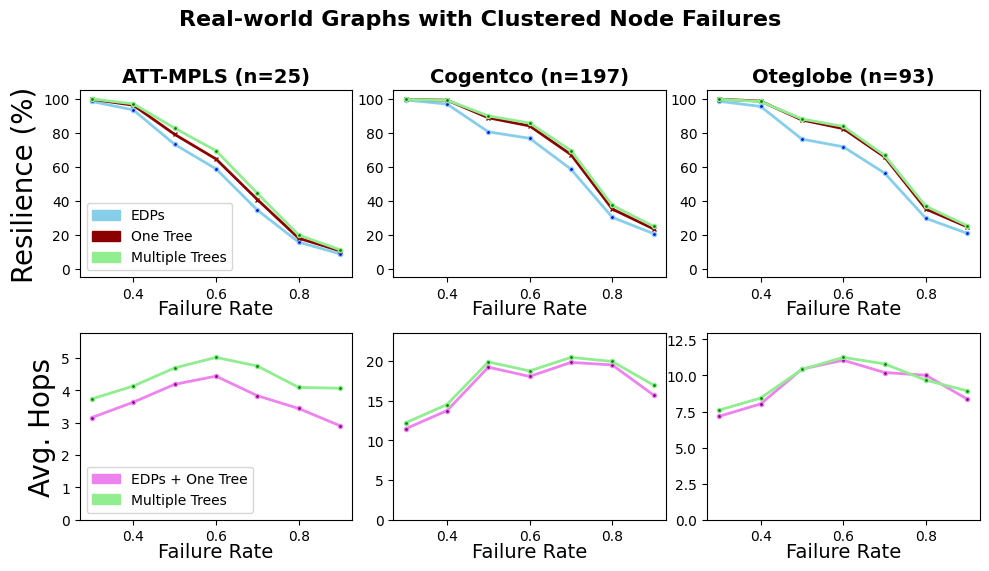

In [12]:
if runs1000_clustered_available:
    clustered_runs1000_grid_path = plot_paper_grid(
        "clustered",
        BA_CLUSTERED_VALUES,
        RUNS1000_SUFFIX,
        "notebook_node_zoo_clustered_paper_runs1000.png",
        "Failure Rate",
        "Real-world Graphs with Clustered Node Failures",
    )
else:
    print("1000-Run clustered CSV-Dateien fehlen noch; Plot wird übersprungen.")

## CSV-Inhaltskontrolle für 1000-Run-Node-Failures

Diese Zelle kontrolliert alle 1000-Run-CSV-Ordner: Random und Clustered Node Failures für ATT-MPLS, Cogentco und Oteglobe. Sie prüft Dateianzahl, Zeilenzahl, Graphgröße, Fehlermodell und ob `nrFailedNodes` vorhanden ist.

In [13]:
def check_csv_contents(failure_model, graph, values, suffix):
    input_dir = result_dir(failure_model, graph, suffix)
    rows = []
    problems = []
    required_columns = {
        "rep", "nrNodes", "nrEdges", "nrPaths", "failureModel",
        "nrFailedNodes", "hopsPath", "hopsRankedOne", "hopsRanked",
    }

    for value, file_name in zip(values, series_files(graph, values)):
        csv_path = input_dir / file_name
        if not csv_path.exists():
            problems.append(f"missing {csv_path.name}")
            continue

        df = pd.read_csv(csv_path)
        missing_columns = sorted(required_columns - set(df.columns))
        if len(df.index) != 1000:
            problems.append(f"{csv_path.name}: rows={len(df.index)}")
        if missing_columns:
            problems.append(f"{csv_path.name}: missing columns={missing_columns}")
        if set(df["nrNodes"].dropna().unique()) != {graph["nodes"]}:
            problems.append(f"{csv_path.name}: wrong nrNodes")
        if set(df["failureModel"].dropna().unique()) != {failure_model}:
            problems.append(f"{csv_path.name}: wrong failureModel")

        rows.append({
            "failure_model": failure_model,
            "graph": graph["label"],
            "failure_value": value,
            "rows": len(df.index),
            "avg_failed_nodes": df["nrFailedNodes"].mean(),
            "EDPs_resilience": (df["hopsPath"] > -1).mean(),
            "OneTree_resilience": (df["hopsRankedOne"] > -1).mean(),
            "MultipleTrees_resilience": (df["hopsRanked"] > -1).mean(),
        })

    return pd.DataFrame(rows), problems


if runs1000_random_available and runs1000_clustered_available:
    all_summaries = []
    all_problems = []

    for graph in REAL_WORLD_GRAPHS:
        summary, problems = check_csv_contents("random", graph, BA_RANDOM_VALUES, "runs1000")
        all_summaries.append(summary)
        all_problems.extend(problems)

        summary, problems = check_csv_contents("clustered", graph, BA_CLUSTERED_VALUES, "runs1000")
        all_summaries.append(summary)
        all_problems.extend(problems)

    csv_content_summary = pd.concat(all_summaries, ignore_index=True)
    readable_check = csv_content_summary.groupby(["failure_model", "graph"]).agg(
        csv_files=("failure_value", "count"),
        rows_per_csv=("rows", "first"),
        all_complete=("rows", lambda rows: bool((rows == 1000).all())),
        avg_failed_nodes_first=("avg_failed_nodes", "first"),
        avg_failed_nodes_last=("avg_failed_nodes", "last"),
    ).reset_index()

    failure_model_order = {"random": 0, "clustered": 1}
    graph_order = {"attmpls": 0, "cogentco": 1, "oteglobe": 2}
    readable_check = readable_check.assign(
        _failure_model_order=readable_check["failure_model"].map(failure_model_order),
        _graph_order=readable_check["graph"].map(graph_order),
    ).sort_values(["_failure_model_order", "_graph_order"]).drop(columns=["_failure_model_order", "_graph_order"]).reset_index(drop=True)

    display(readable_check)

    if all_problems:
        print("Probleme gefunden:")
        for problem in all_problems[:30]:
            print("-", problem)
    else:
        print("Alle 1000-Run-CSV-Dateien sind inhaltlich plausibel.")
else:
    print("1000-Run CSV-Dateien fehlen noch; Inhaltskontrolle wird übersprungen.")

,failure_model,graph,csv_files,rows_per_csv,all_complete,avg_failed_nodes_first,avg_failed_nodes_last
0,random,attmpls,10,1000,True,2.059,16.534
1,random,cogentco,10,1000,True,0.709,7.280
2,random,oteglobe,10,1000,True,0.586,5.580
3,clustered,attmpls,7,1000,True,0.695,11.200
4,clustered,cogentco,7,1000,True,0.108,5.651
5,clustered,oteglobe,7,1000,True,0.144,5.709


Alle 1000-Run-CSV-Dateien sind inhaltlich plausibel.
